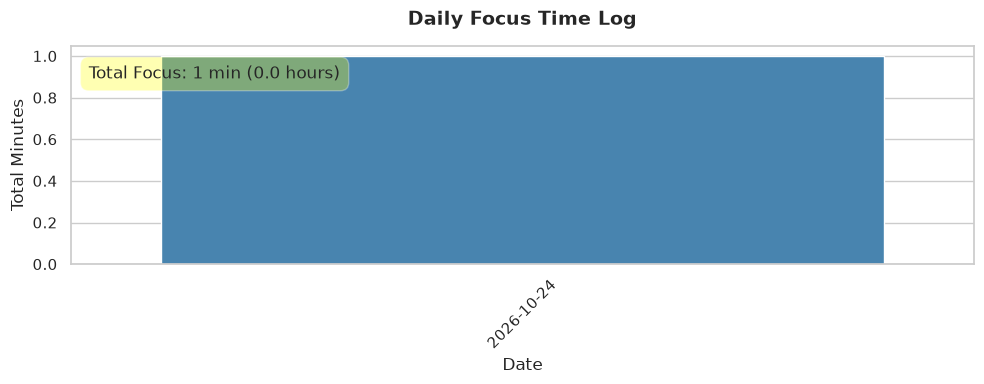

In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# グラフのスタイル設定
sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(figsize=(10, 4))

csv_path = "/home/mrsmmori/notebooks/outputs/focustime.csv"

try:
    # CSV読み込み
    df = pd.read_csv(csv_path)
    
    if df.empty:
        print("データがまだありません。タイマーを実行して記録を作ってみましょう！")
    else:
        # Timestampを日付型に変換
        df['Timestamp'] = pd.to_datetime(df['Timestamp'])
        df['Date'] = df['Timestamp'].dt.date
        
        # 日ごとに集中時間を合計 (Minutes)
        daily_df = df.groupby('Date')['Minutes'].sum().reset_index()
        
        # グラフ描画（hueとlegendを追加して警告を解消）
        sns.barplot(
            data=daily_df, 
            x='Date', 
            y='Minutes', 
            hue='Date',          # 警告対策: xと同じ変数を指定
            palette='Blues_d', 
            legend=False,        # 警告対策: 凡例を非表示にする
            ax=ax
        )
        
        # タイトルから絵文字を外して文字化け・警告を解消
        ax.set_title("Daily Focus Time Log", fontsize=14, fontweight='bold', pad=15)
        ax.set_xlabel("Date", fontsize=12)
        ax.set_ylabel("Total Minutes", fontsize=12)
        plt.xticks(rotation=45)
        
        # 合計集中時間のテキスト表示
        total_all_time = df['Minutes'].sum()
        total_hours = total_all_time / 60
        ax.text(
            0.02, 0.85, 
            f"Total Focus: {total_all_time} min ({total_hours:.1f} hours)", 
            transform=ax.transAxes, 
            fontsize=12, 
            bbox=dict(boxstyle='round,pad=0.5', facecolor='yellow', alpha=0.3)
        )
        
        plt.tight_layout()
        plt.show()

except FileNotFoundError:
    print(f"CSVファイルが見つかりません: {csv_path}")